**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 6**
Ingeniería de características (FE)

---

## Integrantes del equipo

| Nombre completo | Matrícula |
| --- | --- |
| Federico Castro Zenteno | A01660986 |
| ______________________________ | __________________ |
| ______________________________ | __________________ |
| ______________________________ | __________________ |

Los espacios restantes se completarán cuando se confirmen los demás integrantes.


En esta actividad trabajarás con el archivo `computer_prices.csv`, basado en un conjunto de datos sobre características técnicas y especificaciones de computadoras portátiles y de escritorio, disponible en Kaggle.

Los datos fueron recopilados para analizar el rendimiento y el precio de los dispositivos, e incluyen información sobre hardware, almacenamiento, conectividad y otras especificaciones técnicas. Los indicadores incluidos son:

* `device_type`: Tipo de dispositivo (ej. laptop, desktop)
* `brand`: Marca del dispositivo
* `model`: Modelo del dispositivo
* `release_year`: Año de lanzamiento del dispositivo
* `os`: Sistema operativo instalado
* `form_factor`: Factor de forma o diseño del dispositivo (ej. laptop, ultrabook, desktop tower)
* `cpu_brand`: Marca del procesador
* `cpu_tier`: Nivel o gama del procesador, ordinal del 1 al 6 según desempeño
* `cpu_cores`: Número de núcleos del procesador
* `cpu_threads`: Número de hilos de ejecución del procesador
* `gpu_brand`: Marca de la tarjeta gráfica
* `gpu_model`: Modelo específico de la tarjeta gráfica
* `gpu_tier`: Nivel o gama de la GPU, ordinal del 1 al 6 según desempeño
* `vram_gb`: Memoria de video de la GPU en gigabytes
* `ram_gb`: Memoria RAM del dispositivo en gigabytes
* `storage_type`: Tipo de almacenamiento (ej. HDD, SSD)
* `storage_gb`: Capacidad de almacenamiento en gigabytes
* `storage_drive_count`: Número de unidades de almacenamiento instaladas
* `display_type`: Tipo de pantalla (ej. IPS, TN, OLED)
* `charger_watts`: Potencia del cargador (en watts) para laptops
* `psu_watts`: Potencia de la fuente de poder (en watts) para desktops
* `wifi`: Estándar de conectividad Wi-Fi (ej. Wi-Fi 5, 6, 6E, 7)
* `bluetooth`: Versión de Bluetooth
* `weight_kg`: Peso del dispositivo en kilogramos
* `warranty_months`: Meses de garantía del dispositivo
* `price`: Precio del dispositivo. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

### Ejecución

Descarga o clona el repositorio completo y abre esta libreta en la misma carpeta que
`computer_prices.csv` y `requirements.txt`. Instala las dependencias con
`pip install -r requirements.txt` y ejecuta todas las celdas en orden.
En Colab, sube el CSV e instala las mismas dependencias antes de ejecutar.

Se fija **2026** como año de referencia para que la antigüedad de los equipos sea
reproducible. Esta versión se reconstruyó a partir de la plantilla original y el
CSV adjunto, porque no fue posible recuperar el archivo completado del chat anterior.


In [1]:
%matplotlib inline
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import probplot
from sklearn.preprocessing import (
    KBinsDiscretizer, FunctionTransformer, PowerTransformer,
    MinMaxScaler, OneHotEncoder, OrdinalEncoder,
)
from category_encoders.binary import BinaryEncoder

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100
REFERENCE_YEAR = 2026


1. Descarga el archivo: `computer_prices.csv` y guarda, en un dataframe (`compu_df`), todos sus registros.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.
* Elimina las variables:
  * `model`: Debido a su altísima cardinalidad, lo que dificulta su uso en análisis y modelado.
  * `cpu_model`: Además de su elevada cardinalidad, su información ya está representada de manera implícita en otras variables como: `cpu_tier`, `cpu_cores` y `cpu_threads`

In [2]:
compu_df = pd.read_csv(Path('computer_prices.csv'))
compu_df.info()
num_cols = compu_df.select_dtypes(include='number').columns
text_cols = compu_df.select_dtypes(exclude='number').columns
display(pd.Series({'Filas': len(compu_df), 'Columnas numéricas': len(num_cols),
                   'Columnas de texto': len(text_cols)}, name='Cantidad').to_frame())
display(compu_df.nunique().rename('Valores únicos').to_frame())
compu_df = compu_df.drop(columns=['model', 'cpu_model'])


<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 27 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   device_type          100000 non-null  str    
 1   brand                100000 non-null  str    
 2   model                100000 non-null  str    
 3   release_year         100000 non-null  int64  
 4   os                   100000 non-null  str    
 5   form_factor          100000 non-null  str    
 6   cpu_brand            100000 non-null  str    
 7   cpu_model            100000 non-null  str    
 8   cpu_tier             100000 non-null  int64  
 9   cpu_cores            100000 non-null  int64  
 10  cpu_threads          100000 non-null  int64  
 11  gpu_brand            100000 non-null  str    
 12  gpu_model            100000 non-null  str    
 13  gpu_tier             100000 non-null  int64  
 14  vram_gb              100000 non-null  int64  
 15  ram_gb               100000 n

,Cantidad
Filas,100000
Columnas numéricas,15
Columnas de texto,12


,Valores únicos
device_type,2
brand,10
model,99036
release_year,8
os,4
form_factor,10
cpu_brand,3
cpu_model,26971
cpu_tier,6
cpu_cores,12


**Respuesta 1.** Hay **100,000 registros y 27 columnas: 15 numéricas y 12 de texto**.
`model` tiene 99,036 valores distintos y `cpu_model`, 26,971. Se eliminan ambas como
indica la actividad, conservando las variables técnicas. La versión de Bluetooth
se interpreta como numérica porque así está almacenada en el CSV.

2. Antes de iniciar con el análisis univariado, verifica si hay valores duplicados y/o faltantes.
* Obtén las estadísticas descriptivas, separado las numéricas y las categóricas. De estas últimas incluye las tablas de frecuencia.
* Genera histogramas para las numéricas y diagramas de barras para las categóricas. Con alta cardinalidad, sólo incluye los 10 valores más frecuentes.

,Cantidad
Filas duplicadas,0
Valores faltantes,0


,Faltantes por columna
device_type,0
brand,0
release_year,0
os,0
form_factor,0
cpu_brand,0
cpu_tier,0
cpu_cores,0
cpu_threads,0
gpu_brand,0


,count,mean,std,min,25%,50%,75%,max
release_year,100000.0,2022.320850,2.025761,2018.00,2021.00,2023.00,2024.00,2025.00
cpu_tier,100000.0,3.153490,1.373175,1.00,2.00,3.00,4.00,6.00
cpu_cores,100000.0,10.515740,5.044092,4.00,6.00,8.00,14.00,28.00
cpu_threads,100000.0,19.372700,9.718426,4.00,12.00,16.00,24.00,56.00
gpu_tier,100000.0,2.991350,1.459643,1.00,2.00,3.00,4.00,6.00
vram_gb,100000.0,6.152180,3.964926,0.00,4.00,6.00,8.00,16.00
ram_gb,100000.0,39.706400,31.902684,8.00,16.00,32.00,64.00,144.00
storage_gb,100000.0,903.936000,774.243654,256.00,512.00,512.00,1024.00,4096.00
storage_drive_count,100000.0,1.524980,0.797284,1.00,1.00,1.00,2.00,4.00
charger_watts,100000.0,61.383450,62.795034,0.00,0.00,65.00,90.00,240.00


,count,unique,top,freq
device_type,100000,2,Laptop,59844
brand,100000,10,Lenovo,15992
os,100000,4,Windows,71817
form_factor,100000,10,Mainstream,17819
cpu_brand,100000,3,Intel,52774
gpu_brand,100000,4,NVIDIA,54712
gpu_model,100000,49,Apple Integrated,18922
storage_type,100000,4,NVMe,45059
display_type,100000,6,LED,32000
wifi,100000,4,Wi-Fi 6,46149


,Frecuencia
device_type,
Laptop,59844
Desktop,40156


...

,Frecuencia
gpu_brand,
NVIDIA,54712
Apple,18922
AMD,15767
Intel,10599


,Frecuencia
gpu_model,
Apple Integrated,18922
RTX 40 70,5743
RTX 30 70,5692
RTX 40 60,5437
RTX 30 60,5314
RTX 30 50,5046
RTX 40 50,4970
RTX 40 80,4676
RTX 30 80,4618


,Frecuencia
storage_type,
NVMe,45059
SSD,24937
HDD,15023
Hybrid,14981


,Frecuencia
display_type,
LED,32000
OLED,21910
IPS,17742
Mini-LED,12188
QLED,10069
VA,6091


,Frecuencia
wifi,
Wi-Fi 6,46149
Wi-Fi 6E,25923
Wi-Fi 5,19926
Wi-Fi 7,8002


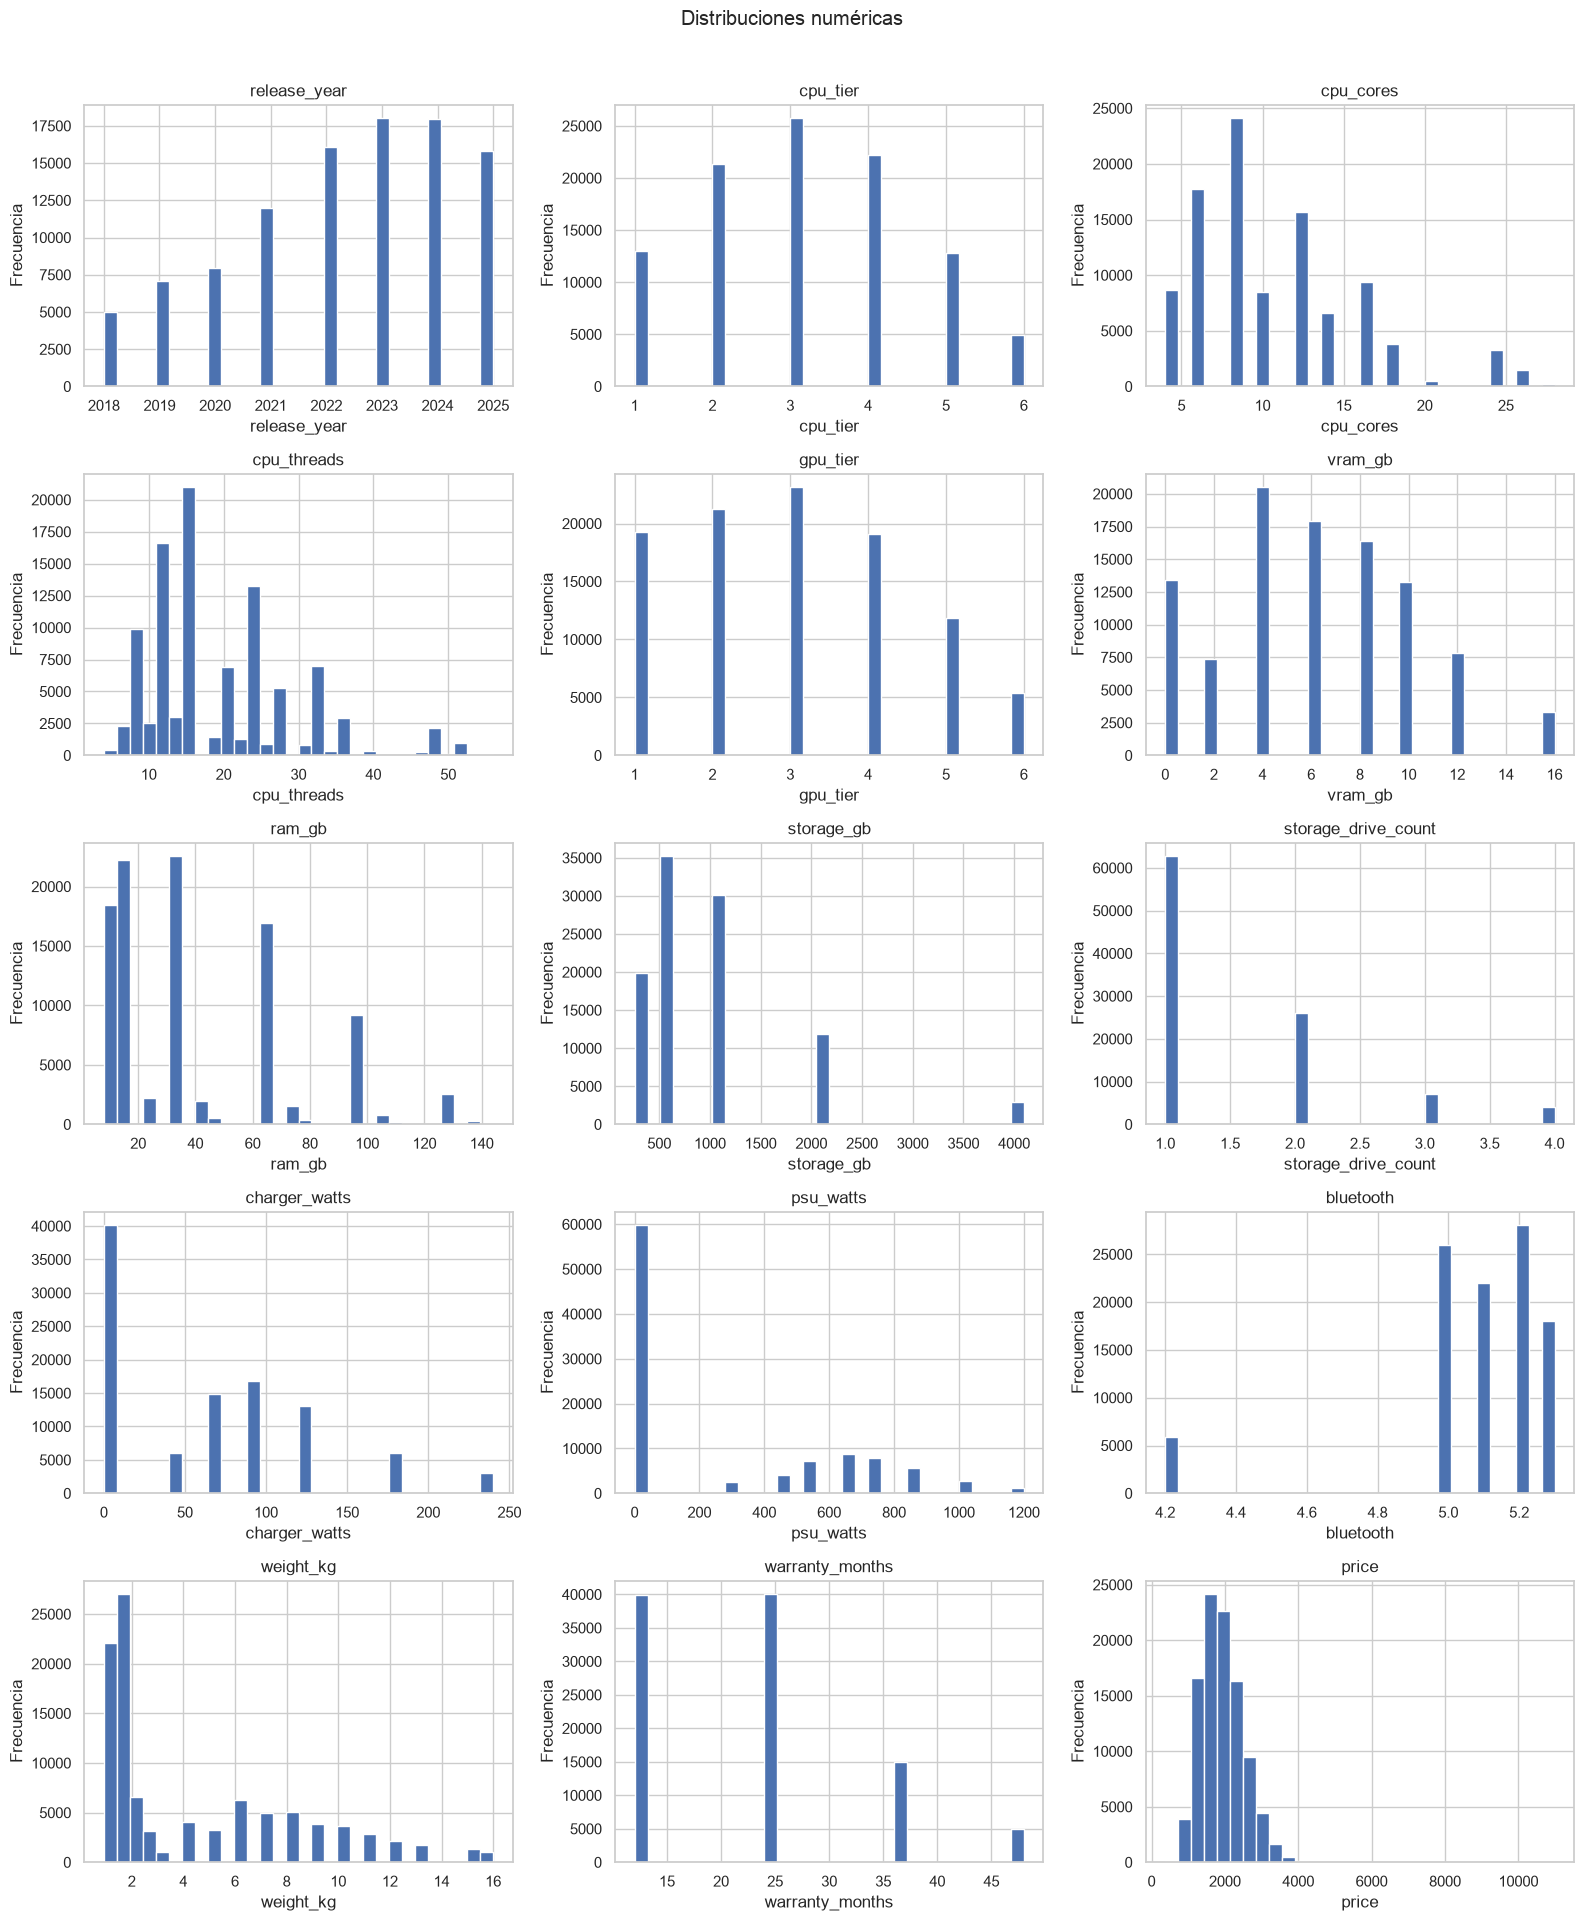

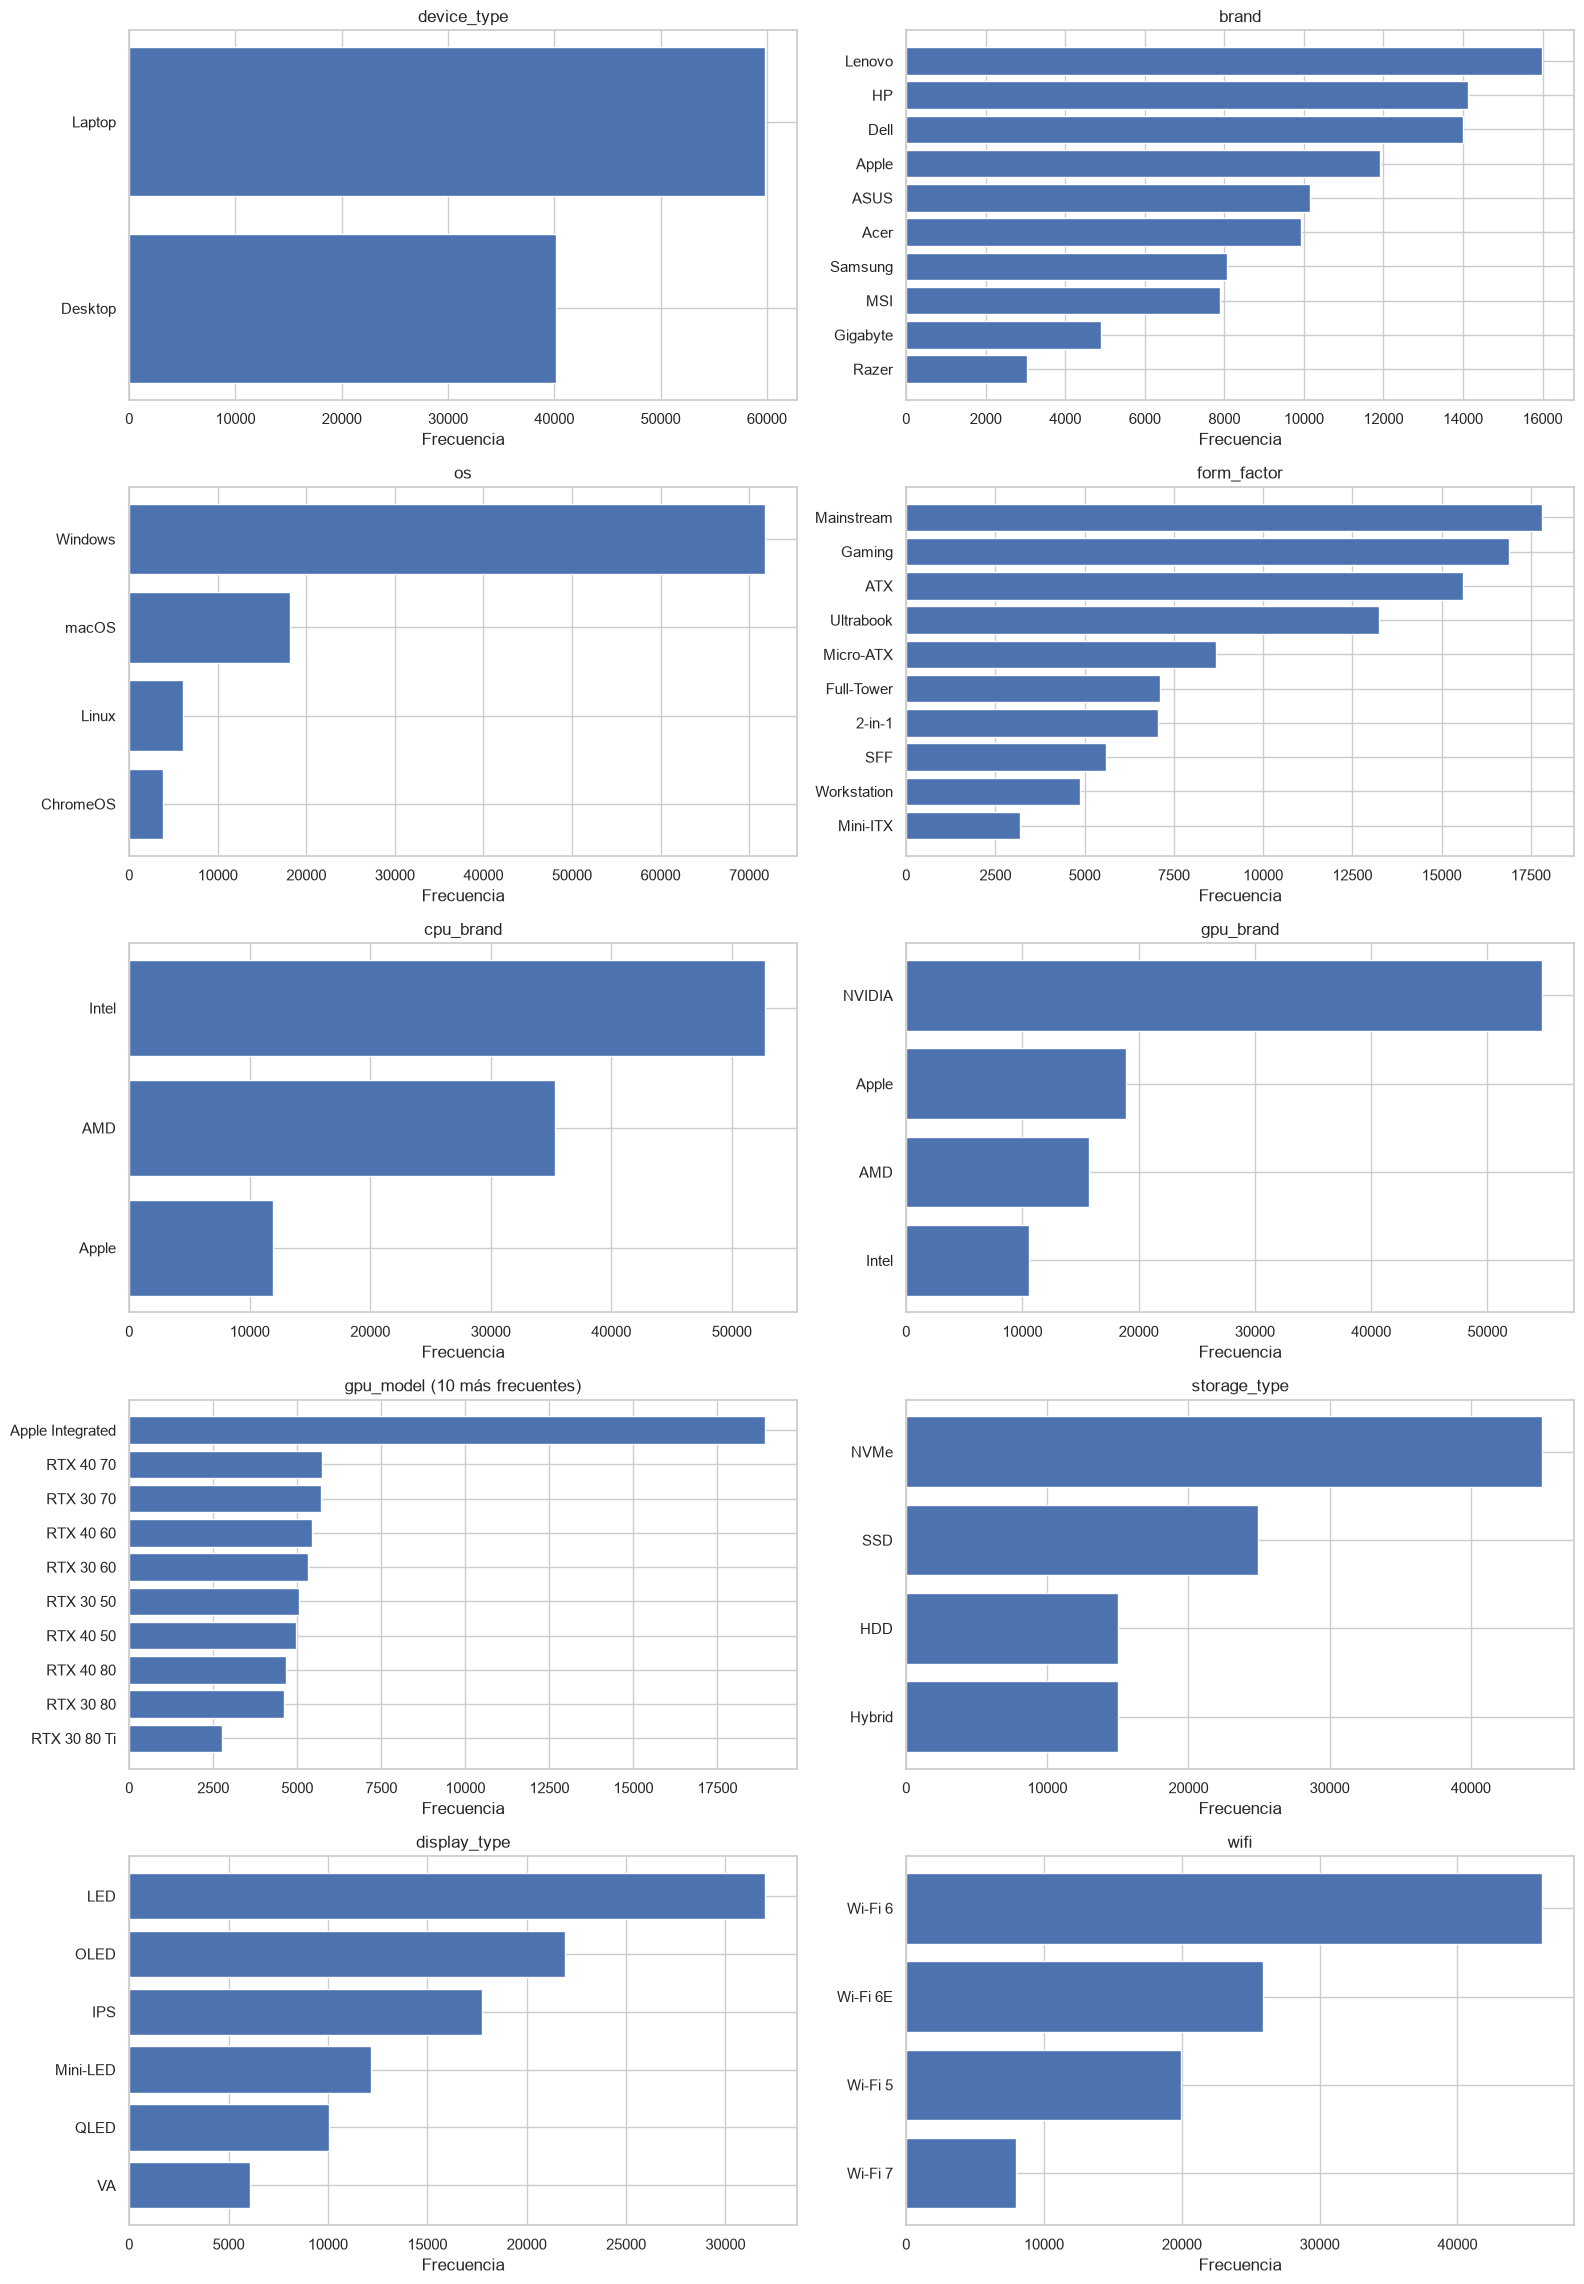

In [3]:
display(pd.Series({'Filas duplicadas': compu_df.duplicated().sum(),
                   'Valores faltantes': compu_df.isna().sum().sum()},
                  name='Cantidad').to_frame())
display(compu_df.isna().sum().rename('Faltantes por columna').to_frame())
num_cols = compu_df.select_dtypes(include='number').columns.tolist()
cat_cols = compu_df.select_dtypes(exclude='number').columns.tolist()
display(compu_df[num_cols].describe().T)
display(compu_df[cat_cols].describe().T)
for col in cat_cols:
    display(compu_df[col].value_counts().rename('Frecuencia').to_frame()
            .rename_axis(col))

fig, axes = plt.subplots(5, 3, figsize=(16, 19))
for ax, col in zip(axes.flat, num_cols):
    ax.hist(compu_df[col], bins=30, edgecolor='white')
    ax.set(title=col, xlabel=col, ylabel='Frecuencia')
for ax in axes.flat[len(num_cols):]:
    ax.set_visible(False)
fig.suptitle('Distribuciones numéricas', y=1.01)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(5, 2, figsize=(16, 23))
for ax, col in zip(axes.flat, cat_cols):
    counts = compu_df[col].value_counts().head(10)
    ax.barh(counts.index.astype(str)[::-1], counts.values[::-1])
    ax.set(title=col + (' (10 más frecuentes)' if compu_df[col].nunique() > 10 else ''),
           xlabel='Frecuencia')
for ax in axes.flat[len(cat_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()


**Respuesta 2.** No hay filas duplicadas ni valores faltantes, por lo que no se
requiere imputación ni eliminación de registros. Después de quitar los dos modelos
quedan 25 columnas. Hay 59,844 laptops y 40,156 computadoras de escritorio.
Las capacidades de RAM, almacenamiento y VRAM toman valores discretos; no conviene
interpretar sus histogramas como distribuciones continuas. `price` presenta asimetría
positiva y una cola derecha; `weight_kg` y las potencias reflejan la mezcla de tipos
de dispositivo. Las barras categóricas muestran hasta diez categorías por variable;
las tablas de frecuencia conservan todas, incluidas las 49 categorías de `gpu_model`.

3. Dibuja un mapa de calor con la matriz de correlación para las variables numéricas del conjunto de datos.
* Identifica los pares de variables cuya correlación sea superior a 0.9 e imprímelos.
* Reflexiona sobre cuáles variables, de las que se imprimieron, representan de manera general la capacidad del hardware y mantenlas; elimina las demás por aportar información redundante.
* Incluye una breve justificación de tus decisiones.

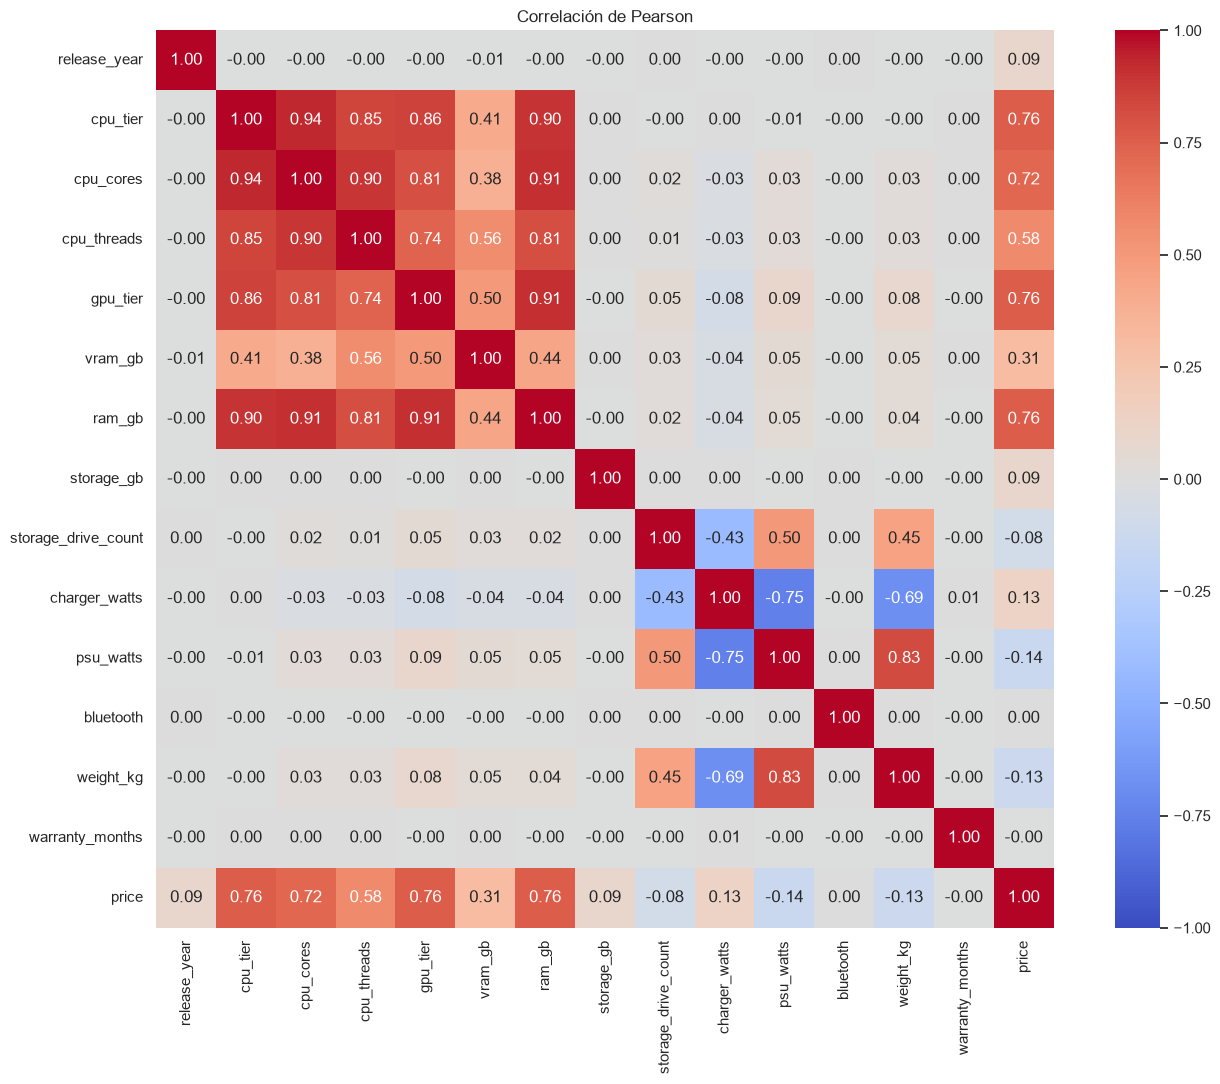

,Variable 1,Variable 2,Correlación
0,cpu_tier,cpu_cores,0.937376
1,cpu_cores,ram_gb,0.906770
2,gpu_tier,ram_gb,0.912918


In [4]:
corr = compu_df.select_dtypes(include='number').corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            vmin=-1, vmax=1, square=True)
plt.title('Correlación de Pearson')
plt.tight_layout()
plt.show()

pares = [(a, b, corr.loc[a, b])
         for i, a in enumerate(corr.columns)
         for b in corr.columns[i + 1:] if abs(corr.loc[a, b]) > 0.9]
pares_df = pd.DataFrame(pares, columns=['Variable 1', 'Variable 2', 'Correlación'])
display(pares_df)
compu_df = compu_df.drop(columns=['cpu_cores', 'ram_gb'])


**Respuesta 3.** Los pares con correlación mayor que 0.9 son
`cpu_tier`–`cpu_cores` (**0.9374**), `cpu_cores`–`ram_gb` (**0.9068**) y
`gpu_tier`–`ram_gb` (**0.9129**). Se revisa el valor absoluto para incluir también
posibles asociaciones negativas fuertes; en este archivo los tres pares son positivos.

Se conservan **`cpu_tier` y `gpu_tier`**, indicadores generales de la gama del hardware,
y se eliminan **`cpu_cores` y `ram_gb`** para retirar la redundancia señalada por estos
pares. `cpu_threads` se conserva porque no supera ese umbral en los pares observados.
La correlación no demuestra causalidad ni equivalencia técnica: la RAM aporta
capacidad propia, pero aquí se retira siguiendo el criterio de selección solicitado.
En un modelo posterior habría que validar esta decisión con datos de entrenamiento.

4. Para comenzar con la ingeniería de características, crea una copia del dataframe y asígnala a un nuevo objeto llamado `compu_transf`.
* Calcula cuántos años han pasado desde el lanzamiento de cada computadora y almacénalo en una nueva columna llamada `years_since_release`; luego, elimina la columna original.
* Utiliza `KBinsDiscretizer` para reemplazar la columna `vram_gb` en 4 bins ordinales basados en cuantiles.
* Imprime los valores que delimitan cada bin y haz un gráfico de barras para ver la cantidad de observaciones en cada uno, con el fin de entender cómo se agruparon los datos.

,Bin,Límite inferior,Límite superior
0,0,0.0,4.0
1,1,4.0,6.0
2,2,6.0,8.0
3,3,8.0,16.0


,Frecuencia
vram_gb,
0.0,20757
1.0,20517
2.0,17930
3.0,40796


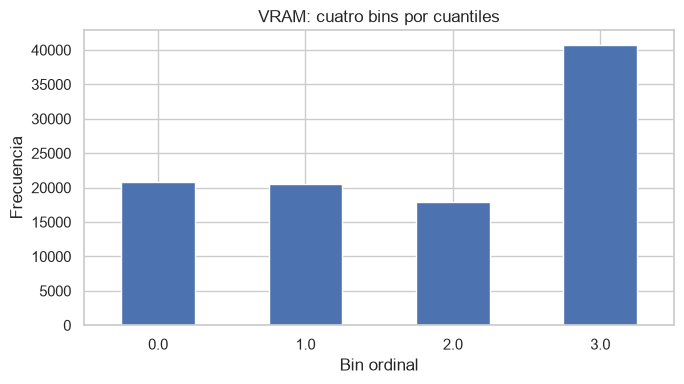

In [5]:
compu_transf = compu_df.copy()
compu_transf['years_since_release'] = REFERENCE_YEAR - compu_transf['release_year']
compu_transf = compu_transf.drop(columns=['release_year'])

discretizador = KBinsDiscretizer(n_bins=4, encode='ordinal', strategy='quantile',
                                quantile_method='linear', subsample=None)
compu_transf['vram_gb'] = discretizador.fit_transform(compu_transf[['vram_gb']]).ravel()
edges = discretizador.bin_edges_[0]
display(pd.DataFrame({'Bin': range(len(edges) - 1),
                      'Límite inferior': edges[:-1], 'Límite superior': edges[1:]}))
display(compu_transf['vram_gb'].value_counts().sort_index()
        .rename('Frecuencia').to_frame())
compu_transf['vram_gb'].value_counts().sort_index().plot.bar(
    title='VRAM: cuatro bins por cuantiles', xlabel='Bin ordinal', ylabel='Frecuencia',
    rot=0, figsize=(7, 4))
plt.tight_layout()
plt.show()


**Respuesta 4.** La antigüedad es `2026 - release_year`; los equipos tienen entre
1 y 8 años. Los límites de los cuatro bins de VRAM son **0, 4, 6, 8 y 16 GB**.
Los intervalos son [0, 4), [4, 6), [6, 8) y [8, 16], con el extremo máximo incluido
en el último. Los tamaños pueden diferir porque muchos dispositivos comparten los
mismos valores de VRAM; discretizar por cuantiles no divide observaciones empatadas.

5. Observa los histogramas del ejercicio 2. Notarás que en las variables `charger_watts` y `psu_watts` aparece una barra en 0. Analiza por qué ocurre esto y qué significa en relación con el tipo de dispositivo.
* Como estas variables son mutuamente excluyentes, combínalas en una nueva columna llamada `power_watts` que contenga la potencia correspondiente de cada dispositivo y, a continuación, haz un histograma para verificar que la distribución resultante es bimodal.
* Por último, borra las columnas originales `charger_watts` y `psu_watts`.

charger_watts = 0,False,True
psu_watts = 0,True,False
device_type,,
Desktop,0,40156
Laptop,59844,0


,min,median,max
device_type,,,
Desktop,300,650.0,1200
Laptop,45,90.0,240


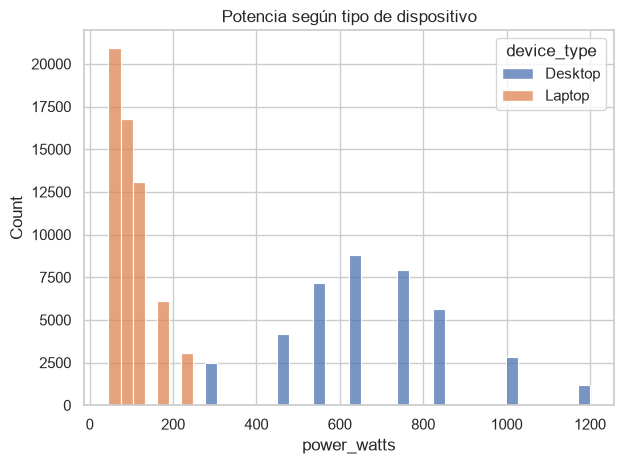

In [6]:
display(pd.crosstab(compu_transf['device_type'],
                    [compu_transf['charger_watts'].eq(0), compu_transf['psu_watts'].eq(0)],
                    colnames=['charger_watts = 0', 'psu_watts = 0']))
assert ((compu_transf['charger_watts'] > 0) ^ (compu_transf['psu_watts'] > 0)).all()
compu_transf['power_watts'] = compu_transf['charger_watts'] + compu_transf['psu_watts']
display(compu_transf.groupby('device_type')['power_watts'].agg(['min', 'median', 'max']))
sns.histplot(data=compu_transf, x='power_watts', hue='device_type',
             bins=40, multiple='stack')
plt.title('Potencia según tipo de dispositivo')
plt.tight_layout()
plt.show()
compu_transf = compu_transf.drop(columns=['charger_watts', 'psu_watts'])


**Respuesta 5.** Los ceros son estructurales: las 40,156 computadoras de escritorio
tienen `charger_watts = 0` y las 59,844 laptops tienen `psu_watts = 0`. No representan
datos faltantes. Como exactamente una de las dos potencias es positiva en cada fila,
su suma recupera la potencia que corresponde al dispositivo.

`power_watts` distingue dos grupos separados: laptops de **45 a 240 W** (mediana
**90 W**) y escritorios de **300 a 1,200 W** (mediana **650 W**). El histograma muestra
esa estructura bimodal general, aunque hay picos adicionales por las potencias
comerciales discretas. Se eliminan las dos columnas originales.

6. Para disminuir el sesgo de la variable `price`, crea tres transformadores: logaritmo, raíz cuadrada y Box - Cox.
* Aplica cada transformador a la variable price, dejando el resultado en variables temporales. El objetivo es comparar los efectos de cada transformación antes de decidir cuál aplicar de manera definitiva sobre las variables continuas del dataframe.
* De la variable original y de cada una de las tres transformaciones se debe mostrar:
  * Histograma: para observar la distribución de los datos.
  * Boxplot: para identificar posibles valores atípicos.
  * Q-Q plot: para evaluar la normalidad de la variable.
  * Skew (sesgo): para cuantificar la asimetría de la distribución.
  * Cantidad de outliers: para conocer cuántos valores extremos existen.
* En función de los resultados obtenidos al comparar las transformaciones, decide cuál logró el mejor efecto sobre la distribución de la variable y aplícala directamente en el dataframe, reemplazando las variables continuas: `weight_kg`, `power_watts` y `price`.

,Sesgo,Outliers (1.5 IQR)
Original,0.986644,976.0
Logaritmo,-0.133105,386.0
Raíz cuadrada,0.332253,364.0
Box-Cox,-0.000238,317.0


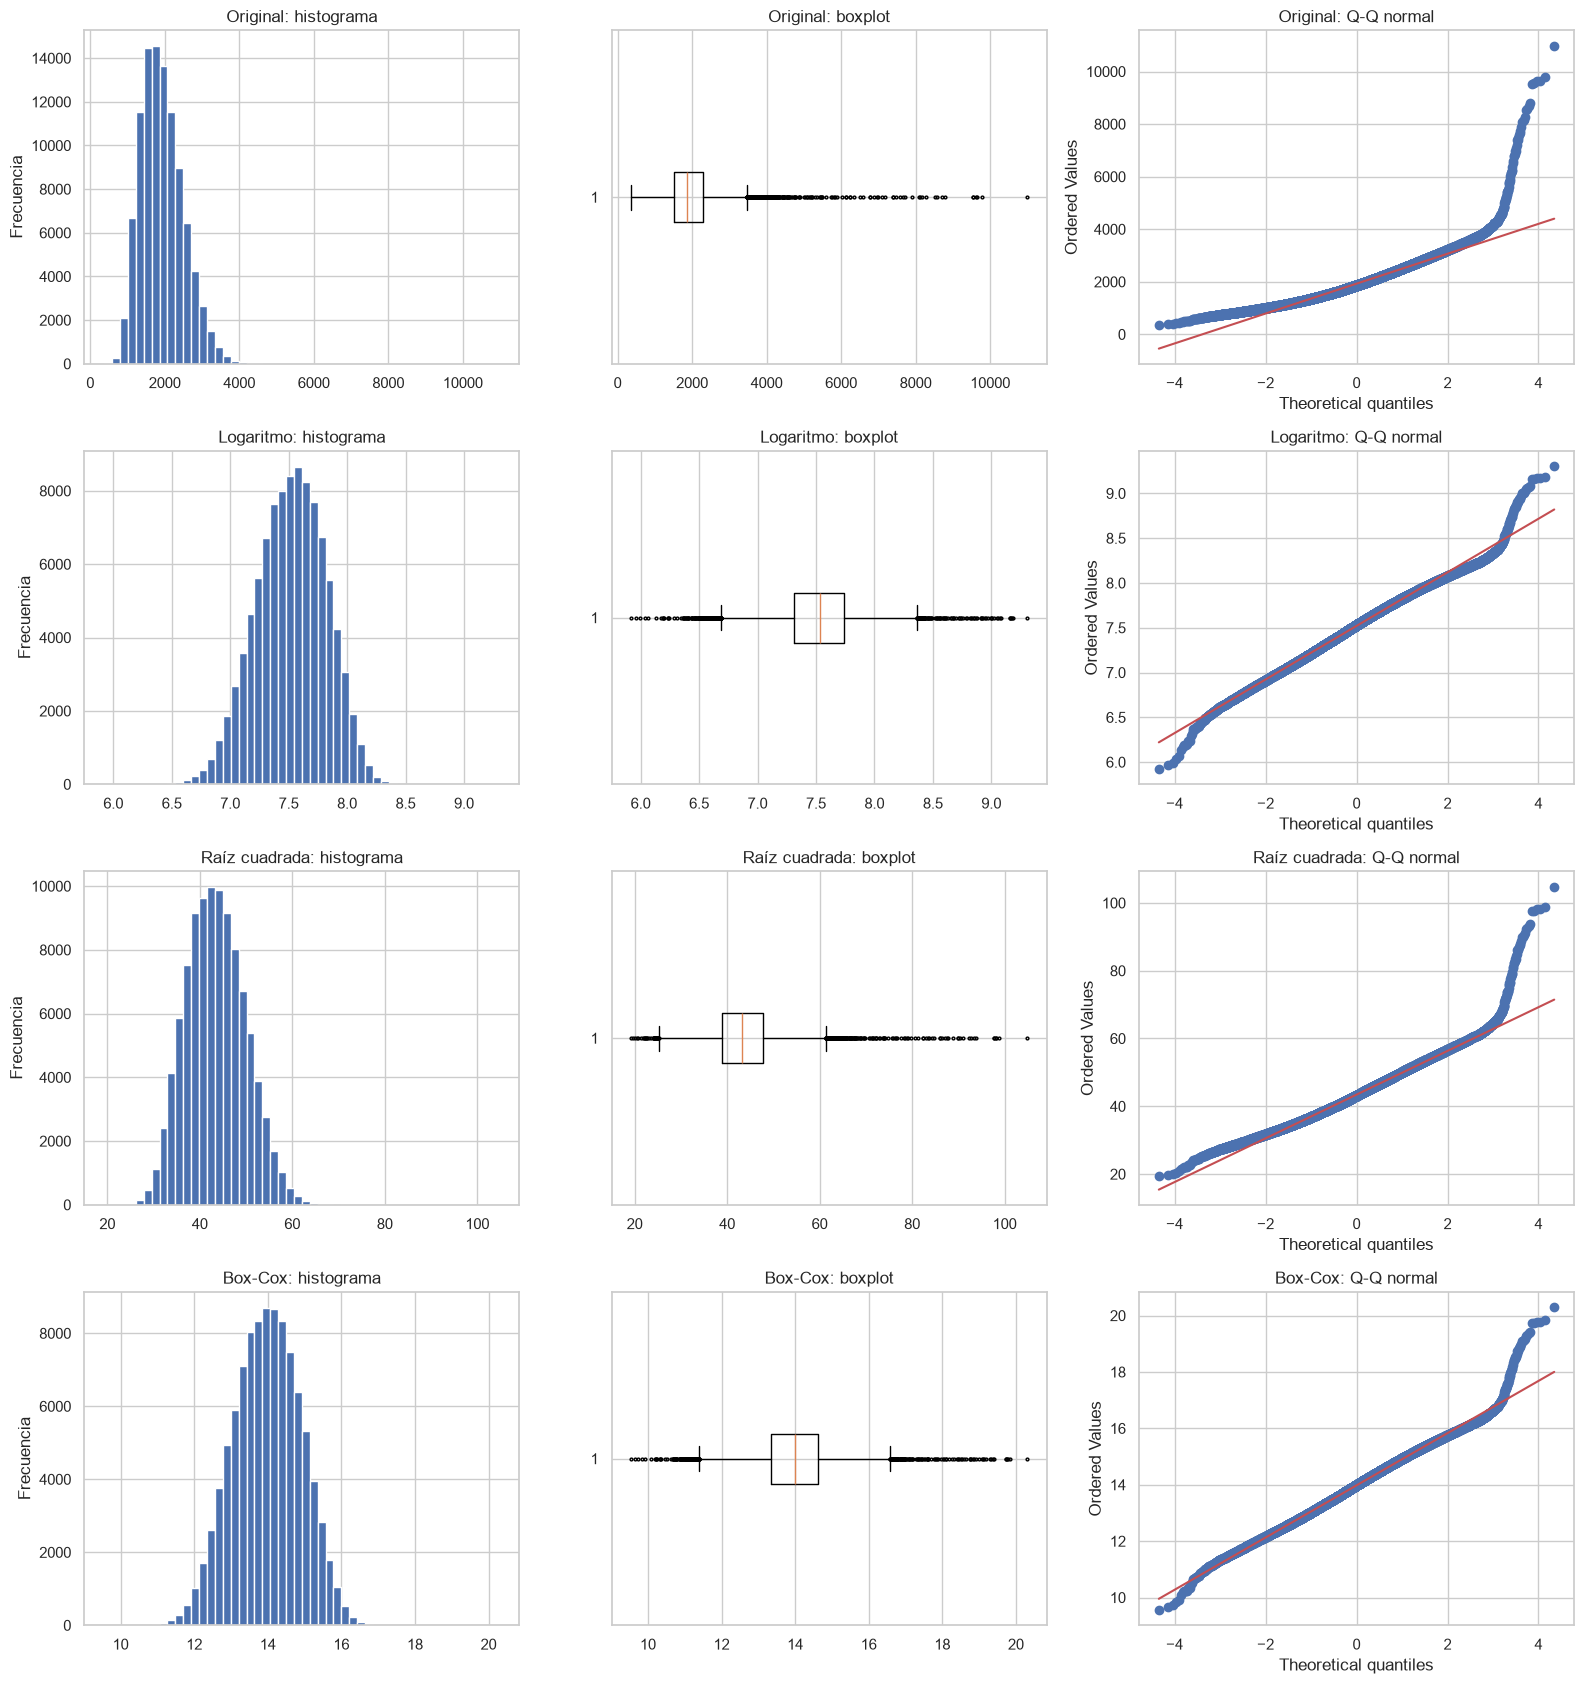

,Lambda Box-Cox
weight_kg,-0.480424
power_watts,-0.165033
price,0.150418


In [7]:
log_transformer = FunctionTransformer(np.log, inverse_func=np.exp, validate=True)
sqrt_transformer = FunctionTransformer(np.sqrt, inverse_func=np.square, validate=True)
boxcox_transformer = PowerTransformer(method='box-cox', standardize=False)
price = compu_transf[['price']]
assert (price > 0).all().all()
price_variants = {
    'Original': price.to_numpy().ravel(),
    'Logaritmo': log_transformer.fit_transform(price.to_numpy()).ravel(),
    'Raíz cuadrada': sqrt_transformer.fit_transform(price.to_numpy()).ravel(),
    'Box-Cox': boxcox_transformer.fit_transform(price).ravel(),
}

def count_outliers(values):
    q1, q3 = np.quantile(values, [0.25, 0.75])
    iqr = q3 - q1
    return int(((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).sum())

comparison = pd.DataFrame({
    name: {'Sesgo': pd.Series(values).skew(), 'Outliers (1.5 IQR)': count_outliers(values)}
    for name, values in price_variants.items()
}).T
display(comparison)

fig, axes = plt.subplots(4, 3, figsize=(16, 17))
for row, (name, values) in enumerate(price_variants.items()):
    axes[row, 0].hist(values, bins=50, edgecolor='white')
    axes[row, 0].set(title=f'{name}: histograma', ylabel='Frecuencia')
    axes[row, 1].boxplot(values, orientation='horizontal', flierprops={'markersize': 2})
    axes[row, 1].set_title(f'{name}: boxplot')
    probplot(values, dist='norm', plot=axes[row, 2])
    axes[row, 2].set_title(f'{name}: Q-Q normal')
plt.tight_layout()
plt.show()

best_transform = comparison.drop(index='Original')['Sesgo'].abs().idxmin()
assert best_transform == 'Box-Cox'
continuous_cols = ['weight_kg', 'power_watts', 'price']
assert (compu_transf[continuous_cols] > 0).all().all()
continuous_transformer = PowerTransformer(method='box-cox', standardize=False)
compu_transf[continuous_cols] = continuous_transformer.fit_transform(
    compu_transf[continuous_cols])
display(pd.Series(continuous_transformer.lambdas_, index=continuous_cols,
                  name='Lambda Box-Cox').to_frame())


**Respuesta 6.** Los valores de `price` son estrictamente positivos, por lo que
las tres transformaciones están definidas. Con el criterio de 1.5 IQR, calculado
por separado en cada distribución, se obtienen:

| Distribución | Sesgo | Outliers |
| --- | ---: | ---: |
| Original | 0.986644 | 976 |
| Logaritmo | -0.133105 | 386 |
| Raíz cuadrada | 0.332253 | 364 |
| Box-Cox | -0.000238 | 317 |

Se selecciona **Box-Cox** porque tiene el sesgo absoluto más cercano a cero y,
además, el menor número de outliers bajo ese criterio. El histograma, el boxplot
y el Q-Q permiten contrastar la mejora de simetría; la cola extrema sigue apartándose
de la recta, por lo que no se afirma normalidad perfecta. Ninguna observación se
elimina: el conteo es una comparación de distribuciones transformadas.

Se aplica Box-Cox a `weight_kg`, `power_watts` y `price`, estimando un lambda propio
para cada columna. La decisión se fundamenta en la comparación de `price`, como
solicita el ejercicio; no implica que Box-Cox sea la mejor opción para cada variable
por separado ni que elimine la mezcla de laptops y escritorios.

7. Para que todas las variables numéricas estén en la misma escala, aplica `MinMaxScaler` de sklearn a todas las columnas numéricas del dataframe, reemplazando las columnas originales.

In [8]:
numeric_cols = compu_transf.select_dtypes(include='number').columns.tolist()
numeric_scaler = MinMaxScaler()
compu_transf[numeric_cols] = numeric_scaler.fit_transform(compu_transf[numeric_cols])
display(compu_transf[numeric_cols].agg(['min', 'max']).T)


,min,max
cpu_tier,0.0,1.0
cpu_threads,0.0,1.0
gpu_tier,0.0,1.0
vram_gb,0.0,1.0
storage_gb,0.0,1.0
storage_drive_count,0.0,1.0
bluetooth,0.0,1.0
weight_kg,0.0,1.0
warranty_months,0.0,1.0
price,0.0,1.0


**Respuesta 7.** Se sustituyen todas las columnas numéricas por su escala
Min-Max. Cada columna observada queda entre 0 y 1. El escalamiento conserva el
orden relativo de los valores y no elimina la multimodalidad.

8. Aunque `wifi` es una variable categórica, sus categorías tienen un orden natural (Wi-Fi 5 < Wi-Fi 6 < Wi-Fi 6E < Wi-Fi 7). Codifícala usando `OrdinalEncoder`.
* Luego, escala la variable codificada entre 0 y 1 con `MinMaxScaler`, para que quede en la misma escala que las variables numéricas del dataframe.

Nota: Ambos cambios deben efectuarse sobre la columna original, de manera que quede una única columna `wifi` con toda la información transformada.

In [9]:
wifi_encoder = OrdinalEncoder(categories=[['Wi-Fi 5', 'Wi-Fi 6', 'Wi-Fi 6E', 'Wi-Fi 7']])
wifi_scaler = MinMaxScaler()
compu_transf['wifi'] = wifi_scaler.fit_transform(
    wifi_encoder.fit_transform(compu_transf[['wifi']])).ravel()
display(pd.DataFrame({'Categoría': wifi_encoder.categories_[0],
                      'Ordinal': range(4), 'Escala 0–1': np.arange(4) / 3}))


,Categoría,Ordinal,Escala 0–1
0,Wi-Fi 5,0,0.000000
1,Wi-Fi 6,1,0.333333
2,Wi-Fi 6E,2,0.666667
3,Wi-Fi 7,3,1.000000


**Respuesta 8.** Se respeta el orden Wi-Fi 5 < Wi-Fi 6 < Wi-Fi 6E < Wi-Fi 7.
Tras escalar, las categorías corresponden a **0, 1/3, 2/3 y 1**, respectivamente,
y se mantiene una única columna `wifi`. Esta codificación representa el orden,
sin afirmar que las diferencias de rendimiento real sean iguales entre estándares.

9. La variable `gpu_model` tiene muchas categorías. Usar *One-Hot Encoding* aumentaría significativamente la dimensionalidad del dataframe. Por ello, utiliza `BinaryEncoder` para codificarla.
* Guarda el resultado en un dataframe llamado `bin_df`. Más adelante, lo combinarás con `compu_transf` para integrar las variables codificadas.

In [10]:
binary_encoder = BinaryEncoder(cols=['gpu_model'], return_df=True)
bin_df = binary_encoder.fit_transform(compu_transf[['gpu_model']])
display(bin_df.head())
display(pd.Series({'Categorías de GPU': compu_transf['gpu_model'].nunique(),
                   'Columnas binarias': bin_df.shape[1]}, name='Cantidad').to_frame())


,gpu_model_0,gpu_model_1,gpu_model_2,gpu_model_3,gpu_model_4,gpu_model_5
0,0,0,0,0,0,1
1,0,0,0,0,1,0
2,0,0,0,0,1,1
3,0,0,0,1,0,0
4,0,0,0,1,0,1


,Cantidad
Categorías de GPU,49
Columnas binarias,6


**Respuesta 9.** Las 49 categorías de `gpu_model` se representan mediante
**6 columnas binarias**, en lugar de las 48 que produciría One-Hot con una referencia.
La codificación se guarda en `bin_df`, con el índice original para combinarla después.
Los bits identifican categorías y no representan una jerarquía de rendimiento.

10. Usa `OneHotEncoder` para codificar las variables categóricas restantes. Asegúrate de usar `drop='first'` para evitar la multicolinealidad y guarda el resultado en un dataframe llamado `ohe_df`
* Combina el dataframe `compu_transf` con las variables categóricas que fueron codificadas en `bin_df` y `ohe_df`. No olvides eliminar las variables originales.
* Usa `describe()` sobre el dataframe resultante para corroborar que todas las columnas estén escaladas entre 0 y 1 y que no queden variables categóricas sin codificar.

In [11]:
remaining_cat_cols = compu_transf.select_dtypes(exclude='number').columns.drop('gpu_model').tolist()
onehot_encoder = OneHotEncoder(drop='first', sparse_output=False, dtype=np.float64)
ohe_df = pd.DataFrame(
    onehot_encoder.fit_transform(compu_transf[remaining_cat_cols]),
    columns=onehot_encoder.get_feature_names_out(remaining_cat_cols),
    index=compu_transf.index,
)
display(ohe_df.head())
compu_transf = pd.concat([
    compu_transf.drop(columns=remaining_cat_cols + ['gpu_model']), bin_df, ohe_df,
], axis=1)
display(compu_transf.describe().T)
display(pd.Series({'Filas': compu_transf.shape[0], 'Columnas': compu_transf.shape[1],
                   'Categóricas restantes': len(compu_transf.select_dtypes(exclude='number').columns),
                   'Valores faltantes': compu_transf.isna().sum().sum()}, name='Cantidad').to_frame())
assert compu_transf.select_dtypes(exclude='number').empty
assert not compu_transf.isna().any().any()
assert np.isfinite(compu_transf.to_numpy()).all()
assert compu_transf.min().min() >= -1e-12
assert compu_transf.max().max() <= 1 + 1e-12
assert len(compu_transf) == 100000


,device_type_Laptop,brand_Acer,brand_Apple,brand_Dell,brand_Gigabyte,brand_HP,brand_Lenovo,brand_MSI,brand_Razer,brand_Samsung,...,gpu_brand_Intel,gpu_brand_NVIDIA,storage_type_Hybrid,storage_type_NVMe,storage_type_SSD,display_type_LED,display_type_Mini-LED,display_type_OLED,display_type_QLED,display_type_VA
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


,count,mean,std,min,25%,50%,75%,max
cpu_tier,100000.0,0.430698,0.274635,0.0,0.200000,0.400000,0.600000,1.0
cpu_threads,100000.0,0.295629,0.186893,0.0,0.153846,0.230769,0.384615,1.0
gpu_tier,100000.0,0.398270,0.291929,0.0,0.200000,0.400000,0.600000,1.0
vram_gb,100000.0,0.595883,0.394170,0.0,0.333333,0.666667,1.000000,1.0
storage_gb,100000.0,0.168733,0.201626,0.0,0.066667,0.066667,0.200000,1.0
storage_drive_count,100000.0,0.174993,0.265761,0.0,0.000000,0.000000,0.333333,1.0
wifi,100000.0,0.406670,0.284834,0.0,0.333333,0.333333,0.666667,1.0
bluetooth,100000.0,0.804331,0.223616,0.0,0.727273,0.818182,0.909091,1.0
weight_kg,100000.0,0.517032,0.293982,0.0,0.280423,0.417162,0.834353,1.0
warranty_months,100000.0,0.283343,0.284219,0.0,0.000000,0.333333,0.333333,1.0


,Cantidad
Filas,100000
Columnas,54
Categóricas restantes,0
Valores faltantes,0


**Respuesta 10.** Se codifican las ocho variables categóricas restantes con
One-Hot y `drop='first'`. Se concatenan las columnas numéricas, las binarias de GPU
y las One-Hot, y se retiran las variables de texto originales. `describe()` y las
comprobaciones finales verifican que se conservan las 100,000 filas, no hay valores
faltantes ni infinitos y todas las columnas son numéricas dentro de [0, 1], con
tolerancia de 1e-12 para redondeo numérico.

La variable objetivo `price` también está transformada y escalada porque así lo
requiere la actividad. Para entrenamiento predictivo posterior se deberá separar
el objetivo y ajustar los transformadores sólo con el conjunto de entrenamiento,
conservando sus parámetros para invertir las predicciones a la escala monetaria.

---
## Declaración de uso de IA

OpenAI. (2026). *Codex, basado en GPT-6* [Modelo de lenguaje grande].
Se utilizó para reconstruir las soluciones a partir de la plantilla y el CSV,
generar y depurar código, redactar análisis, verificar la ejecución secuencial,
agregar los datos del equipo y preparar la publicación en GitHub.
https://openai.com/codex/

El equipo deberá revisar los resultados y completar los datos de los demás integrantes
antes de la entrega académica.
